# Лабораторная работа 4.1. Задача Коши для ОДУ второго порядка

**Вариант 7.** Решить задачу Коши методами Эйлера, Рунге-Кутты и Адамса 4-го порядка:

$$y'' - 4x\,y' + (4x^2 - 2)\,y = 0,\qquad y(0)=1,\quad y'(0)=1,\qquad x\in[0,\;1],\quad h=0.1 .$$

In [1]:
import json
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"

### Вспомогательные функции: чтение данных и оформление вывода

In [2]:
def read_data(name: str) -> dict:
    """Читает JSON-файл с исходными данными."""
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"файл '{path}' не найден: положите папку data рядом с ноутбуком")
    with open(path, encoding="utf-8") as file:
        return json.load(file)


def scalar(data: dict, key: str) -> float:
    """Читает одно вещественное число по ключу."""
    if key not in data:
        raise ValueError(f"в исходных данных нет ключа '{key}'")
    return float(data[key])


def number(value: float, precision: int = 6) -> str:
    """Число в едином формате; машинный нуль печатается как 0."""
    value = float(value)
    if abs(value) < 0.5 * 10 ** (-precision):
        value = 0.0
    return f"{value:.{precision}f}"


def table(rows: list[list], headers: list[str], title: str | None = None) -> None:
    """Печатает таблицу (pandas используется только для оформления)."""
    if title:
        print(title)
    display(pd.DataFrame(rows, columns=headers).style.hide(axis="index"))


def check(title: str, deviation: float, tolerance: float = 1e-8) -> None:
    """Печатает вердикт проверки по наибольшему отклонению."""
    verdict = "ВЫПОЛНЕНО" if deviation <= tolerance else "НЕ ВЫПОЛНЕНО"
    print(f"  {title}: макс. отклонение = {deviation:.3e}  ->  {verdict}")

### Правая часть системы и точное решение

Точное решение $y = (1+x)e^{x^2}$ даёт производную
$y' = e^{x^2}\,(1 + 2x + 2x^2)$ — она понадобится для контроля второй компоненты решения.

In [3]:
def rhs(x: float, u: np.ndarray) -> np.ndarray:
    """Правая часть системы: u = (y, z), z = y'."""
    y, z = u
    return np.array([z, 4.0 * x * z - (4.0 * x * x - 2.0) * y])


def exact(x: float) -> float:
    """Точное решение задачи Коши."""
    return (1.0 + x) * math.exp(x * x)


def exact_derivative(x: float) -> float:
    """Производная точного решения: y' = exp(x^2)*(1 + 2x + 2x^2)."""
    return math.exp(x * x) * (1.0 + 2.0 * x + 2.0 * x * x)

### Реализация методов

In [4]:
def grid_of(left: float, right: float, step: float) -> np.ndarray:
    """Равномерная сетка; шаг должен укладываться целое число раз."""
    count = (right - left) / step
    if abs(count - round(count)) > 1e-9:
        raise ValueError(f"шаг {step} не укладывается целое число раз в [{left}, {right}]")
    return left + step * np.arange(round(count) + 1)


def euler(left: float, right: float, step: float, start: np.ndarray):
    """Метод Эйлера: u(k+1) = u(k) + h*f(x(k), u(k)); первый порядок точности."""
    x = grid_of(left, right, step)
    values = np.zeros((len(x), len(start)))
    values[0] = start
    for k in range(len(x) - 1):
        values[k + 1] = values[k] + step * rhs(x[k], values[k])
    return x, values


def runge_kutta(left: float, right: float, step: float, start: np.ndarray):
    """Метод Рунге-Кутты 4-го порядка: усреднение четырёх пробных наклонов."""
    x = grid_of(left, right, step)
    values = np.zeros((len(x), len(start)))
    values[0] = start
    for k in range(len(x) - 1):
        u = values[k]
        k1 = rhs(x[k], u)
        k2 = rhs(x[k] + step / 2.0, u + step / 2.0 * k1)
        k3 = rhs(x[k] + step / 2.0, u + step / 2.0 * k2)
        k4 = rhs(x[k] + step, u + step * k3)
        values[k + 1] = u + step / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    return x, values


def adams(left: float, right: float, step: float, start: np.ndarray):
    """Явный метод Адамса 4-го порядка; первые три шага считаются методом Рунге-Кутты."""
    x = grid_of(left, right, step)
    if len(x) < 5:
        raise ValueError("для метода Адамса нужно не менее четырёх шагов сетки")
    values = np.zeros((len(x), len(start)))
    values[:4] = runge_kutta(left, left + 3.0 * step, step, start)[1]

    derivatives = [rhs(x[k], values[k]) for k in range(4)]
    for k in range(3, len(x) - 1):
        values[k + 1] = values[k] + step / 24.0 * (55.0 * derivatives[k]
                                                   - 59.0 * derivatives[k - 1]
                                                   + 37.0 * derivatives[k - 2]
                                                   - 9.0 * derivatives[k - 3])
        derivatives.append(rhs(x[k + 1], values[k + 1]))
    return x, values


def runge_romberg(coarse: np.ndarray, fine: np.ndarray, order: int):
    """Уточнение по Рунге-Ромбергу и оценка погрешности решения с шагом h/2."""
    refined = fine + (fine - coarse) / (2.0 ** order - 1.0)
    return refined, np.abs(refined - fine)


def max_error(x: np.ndarray, values: np.ndarray) -> float:
    """Наибольшее отклонение численного решения от точного по всем узлам."""
    return float(max(abs(values[k, 0] - exact(x[k])) for k in range(len(x))))


METHODS = (
    ("Метод Эйлера", euler, 1),
    ("Метод Рунге-Кутты 4-го порядка", runge_kutta, 4),
    ("Метод Адамса 4-го порядка", adams, 4),
)

### Исходные данные

In [5]:
data = read_data("lab4_1.json")
left = scalar(data, "left")
right = scalar(data, "right")
step = scalar(data, "h")
start = np.array([scalar(data, "y0"), scalar(data, "dy0")])

print("Уравнение:  y'' - 4x*y' + (4x^2 - 2)*y = 0")
print(f"Начальные условия: y({left:g}) = {start[0]:g},  y'({left:g}) = {start[1]:g}")
print(f"Отрезок: [{left:g}, {right:g}],  шаг h = {step:g},  узлов {len(grid_of(left, right, step))}")
print("Точное решение: y = (1 + x)*exp(x^2)")
print()
print("Система первого порядка (u = (y, z), z = y'):")
print("   y' = z")
print("   z' = 4x*z - (4x^2 - 2)*y")

Уравнение:  y'' - 4x*y' + (4x^2 - 2)*y = 0
Начальные условия: y(0) = 1,  y'(0) = 1
Отрезок: [0, 1],  шаг h = 0.1,  узлов 11
Точное решение: y = (1 + x)*exp(x^2)

Система первого порядка (u = (y, z), z = y'):
   y' = z
   z' = 4x*z - (4x^2 - 2)*y


### Решение каждым методом

In [6]:
results = []
halved = []
for title, solver, order in METHODS:
    x, values = solver(left, right, step, start)
    results.append((title, order, x, values))
    halved.append(solver(left, right, step / 2.0, start))

    rows = [[k, number(x[k], 2), number(values[k, 0], 8), number(values[k, 1], 8),
             number(exact(x[k]), 8), f"{abs(values[k, 0] - exact(x[k])):.3e}"]
            for k in range(len(x))]
    table(rows, ["k", "x_k", "y_k", "z_k = y'_k", "точное y(x_k)", "|y_k - y(x_k)|"],
          f"{title}  (порядок точности p = {order})")
    print(f"  Максимальная погрешность: {max_error(x, values):.3e}")
    print()

Метод Эйлера  (порядок точности p = 1)


k,x_k,y_k,z_k = y'_k,точное y(x_k),|y_k - y(x_k)|
0,0.00,1.00000000,1.00000000,1.00000000,0.000e+00
1,0.10,1.10000000,1.20000000,1.11105518,1.106e-02
2,0.20,1.22000000,1.46360000,1.24897293,2.897e-02
3,0.30,1.36636000,1.80516800,1.42242657,5.607e-02
4,0.40,1.54687680,2.24587120,1.64291522,9.604e-02
5,0.50,1.77146392,2.81558584,1.92603813,1.546e-01
6,0.60,2.05302250,3.55584940,2.29332706,2.403e-01
7,0.70,2.40860744,4.52422251,2.77493757,3.663e-01
8,0.80,2.86102969,5.80063924,3.41366558,5.526e-01
9,0.90,3.44109362,7.49662614,4.27102517,8.299e-01


  Максимальная погрешность: 1.246e+00

Метод Рунге-Кутты 4-го порядка  (порядок точности p = 4)


k,x_k,y_k,z_k = y'_k,точное y(x_k),|y_k - y(x_k)|
0,0.00,1.00000000,1.00000000,1.00000000,0.000e+00
1,0.10,1.11105341,1.23226042,1.11105518,1.775e-06
2,0.20,1.24896864,1.54039677,1.24897293,4.289e-06
3,0.30,1.42241833,1.94762175,1.42242657,8.236e-06
4,0.40,1.64290045,2.48782369,1.64291522,1.477e-05
5,0.50,1.92601224,3.21002262,1.92603813,2.589e-05
6,0.60,2.29328205,4.18523903,2.29332706,4.502e-05
7,0.70,2.77485941,5.51706539,2.77493757,7.816e-05
8,0.80,3.41352971,7.35802890,3.41366558,1.359e-04
9,0.90,4.27078838,9.93514561,4.27102517,2.368e-04


  Максимальная погрешность: 4.142e-04

Метод Адамса 4-го порядка  (порядок точности p = 4)


k,x_k,y_k,z_k = y'_k,точное y(x_k),|y_k - y(x_k)|
0,0.00,1.00000000,1.00000000,1.00000000,0.000e+00
1,0.10,1.11105341,1.23226042,1.11105518,1.775e-06
2,0.20,1.24896864,1.54039677,1.24897293,4.289e-06
3,0.30,1.42241833,1.94762175,1.42242657,8.236e-06
4,0.40,1.64254092,2.48662780,1.64291522,3.743e-04
5,0.50,1.92487085,3.20642322,1.92603813,1.167e-03
6,0.60,2.29087365,4.17747437,2.29332706,2.453e-03
7,0.70,2.77028512,5.50202445,2.77493757,4.652e-03
8,0.80,3.40527831,7.33022843,3.41366558,8.387e-03
9,0.90,4.25632774,9.88503048,4.27102517,1.470e-02


  Максимальная погрешность: 2.536e-02



### Оценка погрешности методом Рунге-Ромберга

In [7]:
rows = []
for (title, order, x, values), (x_half, values_half) in zip(results, halved):
    refined, estimate = runge_romberg(values[:, 0], values_half[::2, 0], order)
    exact_values = np.array([exact(point) for point in x])
    rows.append([title, order,
                 f"{max_error(x, values):.3e}",
                 f"{max_error(x_half, values_half):.3e}",
                 f"{float(np.abs(estimate).max()):.3e}",
                 f"{float(np.abs(refined - exact_values).max()):.3e}"])

table(rows, ["метод", "p", "макс.|y(h) - точн|", "макс.|y(h/2) - точн|",
             "оценка Р-Р для h/2", "макс.|Р-Р - точн|"],
      f"Расчёт повторён с шагами h = {step:g} и h/2 = {step / 2:g}")
print("Уточнение: y = y(h/2) + (y(h/2) - y(h)) / (2^p - 1)")

Расчёт повторён с шагами h = 0.1 и h/2 = 0.05


метод,p,макс.|y(h) - точн|,макс.|y(h/2) - точн|,оценка Р-Р для h/2,макс.|Р-Р - точн|
Метод Эйлера,1,1.246e+00,7.231e-01,5.227e-01,2.004e-01
Метод Рунге-Кутты 4-го порядка,4,4.142e-04,2.883e-05,2.569e-05,3.138e-06
Метод Адамса 4-го порядка,4,2.536e-02,2.453e-03,1.527e-03,9.263e-04


Уточнение: y = y(h/2) + (y(h/2) - y(h)) / (2^p - 1)


### Сравнение методов

In [8]:
rows = [[title, order, number(values[-1, 0], 8), number(exact(x[-1]), 8),
         f"{abs(values[-1, 0] - exact(x[-1])):.3e}", f"{max_error(x, values):.3e}"]
        for title, order, x, values in results]
table(rows, ["метод", "p", "y(b)", "точное y(b)", "|погрешность в b|", "макс. погрешность"],
      "Сравнение на правом конце отрезка и по всей сетке")

best = min(results, key=lambda item: max_error(item[2], item[3]))
print(f"Наиболее точный метод: {best[0]}.")
print("Метод Эйлера имеет первый порядок точности и на том же шаге уступает методам")
print("четвёртого порядка на несколько порядков величины. Метод Адамса при равном порядке")
print("уступает Рунге-Кутте: он использует значения с предыдущих шагов, и константа в его")
print("остаточном члене больше.")

Сравнение на правом конце отрезка и по всей сетке


метод,p,y(b),точное y(b),|погрешность в b|,макс. погрешность
Метод Эйлера,1,4.19075623,5.43656366,1.246e+00,1.246e+00
Метод Рунге-Кутты 4-го порядка,4,5.43614949,5.43656366,4.142e-04,4.142e-04
Метод Адамса 4-го порядка,4,5.41120622,5.43656366,2.536e-02,2.536e-02


Наиболее точный метод: Метод Рунге-Кутты 4-го порядка.
Метод Эйлера имеет первый порядок точности и на том же шаге уступает методам
четвёртого порядка на несколько порядков величины. Метод Адамса при равном порядке
уступает Рунге-Кутте: он использует значения с предыдущих шагов, и константа в его
остаточном члене больше.


### Графики

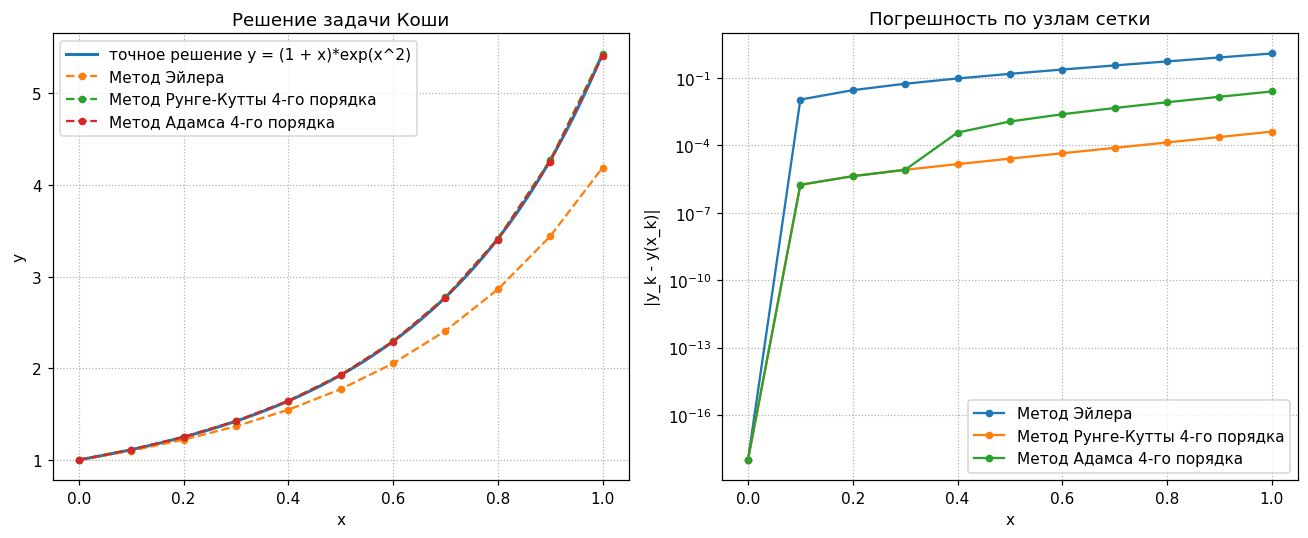

In [9]:
dense = np.linspace(left, right, 400)
figure, (axes_left, axes_right) = plt.subplots(1, 2, figsize=(12, 5))

axes_left.plot(dense, [exact(point) for point in dense], linewidth=2,
               label="точное решение y = (1 + x)*exp(x^2)")
for title, _order, x, values in results:
    axes_left.plot(x, values[:, 0], "o--", markersize=4, label=title)
axes_left.set_title("Решение задачи Коши")
axes_left.set_xlabel("x"); axes_left.set_ylabel("y")

for title, _order, x, values in results:
    errors = [max(abs(values[k, 0] - exact(x[k])), 1e-18) for k in range(len(x))]
    axes_right.semilogy(x, errors, "o-", markersize=4, label=title)
axes_right.set_title("Погрешность по узлам сетки")
axes_right.set_xlabel("x"); axes_right.set_ylabel("|y_k - y(x_k)|")

for axes in (axes_left, axes_right):
    axes.grid(True, linestyle=":")
    axes.legend()
figure.tight_layout()
plt.show()